# AlphaForge: solve for portfolio weights $w$
A reproducible demonstration of **AlphaForge_Constraint_Mapping_with_Financial_Metrics.docx**, using the six local starter CSVs. All profile limits below are **illustrative assumptions**, not inferred investor requirements.

## Goal
Calculate the indicators first, then maximize estimated monthly return after an assumed trading cost under different constraints. “Best” means best for this objective and these estimates—not highest future profit. The final year is held out for evaluation.

## Setup
Select the project `.venv/bin/python` kernel. For a fresh environment, install `numpy pandas scipy matplotlib cvxpy clarabel nbformat ipykernel`. Run all cells from the project root or `alphaforge_starter`.

The notebook reads local data only. It writes tables and figures into `notebook_outputs/`.

In [1]:
from pathlib import Path
import hashlib
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cvxpy as cp
from IPython.display import display, Markdown

ROOT = Path.cwd() if (Path.cwd() / 'alphaforge_starter').exists() else Path.cwd().parent
DATA = ROOT / 'alphaforge_starter'
OUT = ROOT / 'notebook_outputs'
OUT.mkdir(exist_ok=True)
assert DATA.is_dir(), 'Run from the project root or alphaforge_starter.'
pd.set_option('display.max_rows', 40)
pd.set_option('display.max_columns', 12)
plt.rcParams.update({'figure.figsize': (10, 4.8), 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False})
ALPHA = 0.95
KAPPA = 0.001                 # 10 bps per dollar of asset buys + sells
SHRINK = 0.50                 # shrink historical means 50% toward universe mean
TOL = 2e-6
print(f'Python {sys.version.split()[0]} | NumPy {np.__version__} | pandas {pd.__version__} | CVXPY {cp.__version__}')
assert 'CLARABEL' in cp.installed_solvers()

Python 3.13.9 | NumPy 2.3.5 | pandas 2.3.3 | CVXPY 1.9.3


## 1. Data and checks
Prices are adjusted for dividends and splits: **do not add dividends or apply splits again**. USD prices are converted to CAD. Source descriptions and file hashes preserve provenance; existing source files are unchanged.

In [2]:
universe = pd.read_csv(DATA / 'assets_universe.csv').set_index('ticker')
tickers = universe.index.tolist()
prices = pd.read_csv(DATA / 'prices_daily.csv', parse_dates=['date'])
fx = pd.read_csv(DATA / 'fx_usdcad_daily.csv', parse_dates=['date']).set_index('date').sort_index()
macro = pd.read_csv(DATA / 'macro_rates.csv', parse_dates=['date'])
actions = pd.read_csv(DATA / 'corporate_actions.csv', parse_dates=['ex_date'])
sources = pd.read_csv(DATA / 'sources_metadata.csv')
assert len(tickers) == 31 and universe.index.is_unique
assert not prices.duplicated(['date', 'ticker']).any()
assert not macro.duplicated(['date', 'series_id']).any()
assert fx.index.is_unique and (fx.usdcad > 0).all()
assert set(prices.ticker) == set(tickers)
assert prices.adj_close.notna().all() and (prices.adj_close > 0).all()
assert (prices.currency == prices.ticker.map(universe.currency)).all()
assert not universe[['asset_class', 'currency', 'market']].isna().any().any()
manifest = pd.DataFrame([{'file': p.name, 'sha256': hashlib.sha256(p.read_bytes()).hexdigest()}
                         for p in sorted(DATA.glob('*.csv'))])
manifest.to_csv(OUT / 'input_manifest.csv', index=False)
display(sources[['file', 'source', 'retrieved_on']])
display(prices.groupby('ticker').agg(first=('date','min'), last=('date','max'), rows=('date','size')))

,file,source,retrieved_on
0,assets_universe.csv,Compiled by organizers; sector labels follow G...,2026-11-13
1,prices_daily.csv,Yahoo Finance via the open-source yfinance Pyt...,2026-11-13
2,corporate_actions.csv,Yahoo Finance via yfinance,2026-11-13
3,fx_usdcad_daily.csv,Bank of Canada Valet API series FXUSDCAD,2026-11-13
4,macro_rates.csv,Bank of Canada Valet API (V39079; BD.CDN.2YR.D...,2026-11-13
5,macro_rates.csv,FRED (Federal Reserve Bank of St. Louis): DFF;...,2026-11-13


,first,last,rows
ticker,,,
AAPL,2021-11-12,2026-11-12,1255
AGG,2021-11-12,2026-11-12,1255
AMZN,2021-11-12,2026-11-12,1255
ATD.TO,2021-11-12,2026-11-12,1255
BTC-USD,2021-11-12,2026-11-12,1827
CNQ.TO,2021-11-12,2026-11-12,1255
CNR.TO,2021-11-12,2026-11-12,1255
CSU.TO,2021-11-12,2026-11-12,1255
ENB.TO,2021-11-12,2026-11-12,1255


### Align currencies and observation times
Use dates with observed prices for all exchange-traded assets and an observed FX quote; no equity price filling. Crypto uses the **previous UTC day's close** so a later same-date UTC close does not enter the equity-close snapshot. This is still an asynchronous research proxy.

Common-session returns include weekend/holiday moves. Annualization uses the training sample's observed sessions per calendar year, rather than assuming 252. Cash accrues over actual calendar days from the previous day's available Canadian overnight rate, treated as an annual effective yield proxy.

In [3]:
local_prices = prices.pivot(index='date', columns='ticker', values='adj_close').reindex(columns=tickers)
crypto = universe.asset_class.eq('crypto')
for ticker in universe.index[crypto]:
    # Calendar-date lookup, not a one-row shift on the trading calendar.
    local_prices[ticker] = local_prices[ticker].reindex(local_prices.index - pd.Timedelta(days=1)).to_numpy()
aligned = local_prices.dropna().index.intersection(fx.index).sort_values()
cad_prices = local_prices.loc[aligned].copy()
usd = universe.currency.eq('USD')
cad_prices.loc[:, usd] = cad_prices.loc[:, usd].mul(fx.loc[aligned, 'usdcad'], axis=0)
returns = cad_prices.pct_change(fill_method=None).iloc[1:]
assert returns.notna().all().all() and np.isfinite(returns.to_numpy()).all()
assert (returns > -1).all().all()
cutoff = cad_prices.index.max() - pd.DateOffset(years=1)
train = returns.loc[returns.index <= cutoff]
test = returns.loc[returns.index > cutoff]
fit_end = train.index[-1]
fit_years = (fit_end - cad_prices.index[0]).days / 365.25
ANN = len(train) / fit_years

rate = macro.loc[macro.series_id.eq('V39079')].set_index('date').value.sort_index() / 100
calendar = pd.date_range(cad_prices.index.min(), cad_prices.index.max(), freq='D')
available_rate = rate.reindex(rate.index.union(calendar)).sort_index().ffill().reindex(calendar).shift(1)
# Only later cash increments are used; the initial date is a wealth baseline.
cash_daily_growth = (1 + available_rate).pow(1 / 365.25)
cash_daily_growth.iloc[0] = 1
assert cash_daily_growth.notna().all()
cash_index = cash_daily_growth.cumprod().reindex(cad_prices.index)
cash_returns = cash_index.pct_change().iloc[1:]
rf_annual = float(available_rate.loc[fit_end])
rf_month = (1 + rf_annual)**(1/12) - 1
rf_session = (1 + rf_annual)**(1/ANN) - 1
print(f'Train: {train.index[0].date()}–{fit_end.date()} ({len(train)} returns)')
print(f'Holdout: {test.index[0].date()}–{test.index[-1].date()} ({len(test)} returns)')
print(f'Annualization: {ANN:.2f} common sessions/year; cash yield proxy at fit date: {rf_annual:.2%}')
print(f'Zero-volume source rows: {(prices.volume == 0).sum()}; largest aligned absolute return: {returns.abs().max().max():.1%}')

Train: 2021-11-16–2025-11-12 (972 returns)
Holdout: 2025-11-13–2026-11-12 (244 returns)
Annualization: 243.50 common sessions/year; cash yield proxy at fit date: 2.25%
Zero-volume source rows: 1; largest aligned absolute return: 25.6%


## 2. Calculate indicators before optimizing
Use SPY in CAD as the benchmark. Estimate monthly arithmetic returns as
$\hat\mu_i = \frac{A}{12}[0.5\bar r_i + 0.5\bar r_{\mathrm{universe}}]$, where $A$ is sessions/year. This is a deliberately simple forecast assumption, not a validated prediction model.

Volatility and tracking error use sample covariance. Beta uses covariance with SPY. VaR and CVaR are **one common-session losses**, not annual losses; CVaR uses fractional tail mass when 5% is not an integer number of observations. Downside deviation has target zero. Cash is deterministic at its fit-date yield in the optimization.

In [4]:
R = train.to_numpy()
n = len(tickers)
benchmark = train['SPY'].to_numpy()
benchmark_index = tickers.index('SPY')
mu_month = (SHRINK * train.mean().mean() + (1 - SHRINK) * train.mean()).to_numpy() * ANN / 12
cov_annual = train.cov().to_numpy() * ANN
centered = R - R.mean(axis=0)
beta = centered.T @ (benchmark - benchmark.mean()) / np.sum((benchmark - benchmark.mean())**2)

# Exact empirical expected shortfall, including fractional boundary observation.
def cvar_loss(r, alpha=ALPHA):
    losses = np.sort(-np.asarray(r))[::-1]
    tail = (1 - alpha) * len(losses)
    k = int(np.floor(tail))
    fraction = tail - k
    return float((losses[:k].sum() + (fraction * losses[k] if k < len(losses) else 0)) / tail)

def path_stats(r, years):
    wealth = np.r_[1.0, np.cumprod(1 + np.asarray(r))]
    drawdown = wealth / np.maximum.accumulate(wealth) - 1
    return wealth[-1]**(1 / years) - 1, float(drawdown.min())

asset_rows = []
for i, ticker in enumerate(tickers):
    r = R[:, i]
    vol = r.std(ddof=1) * np.sqrt(ANN)
    downside = np.sqrt(np.mean(np.minimum(r, 0)**2) * ANN)
    cagr, mdd = path_stats(r, fit_years)
    asset_rows.append({'ticker': ticker, 'forecast monthly %': 100*mu_month[i],
        'vol annual %': 100*vol, 'beta vs SPY': beta[i],
        'VaR95 session %': 100*np.quantile(-r, ALPHA), 'CVaR95 session %': 100*cvar_loss(r),
        'downside annual %': 100*downside, 'Sharpe': (r.mean()-rf_session)*ANN/vol,
        'alpha annual %': 100*ANN*(r.mean()-rf_session-beta[i]*(benchmark.mean()-rf_session)),
        'CAGR %': 100*cagr, 'max drawdown %': 100*mdd})
indicators = pd.DataFrame(asset_rows).set_index('ticker')
indicators.to_csv(OUT / 'asset_indicators.csv')
display(indicators[['forecast monthly %','vol annual %','beta vs SPY','CVaR95 session %','downside annual %']].round(3))

,forecast monthly %,vol annual %,beta vs SPY,CVaR95 session %,downside annual %
ticker,,,,,
RY.TO,1.392,15.450,0.431,2.344,10.896
TD.TO,1.190,17.658,0.404,2.722,12.941
MFC.TO,1.710,21.990,0.695,3.194,15.339
ENB.TO,1.329,15.532,0.250,2.477,11.267
CNQ.TO,1.710,29.971,0.520,4.503,21.190
CNR.TO,0.701,19.400,0.562,2.891,13.994
FTS.TO,1.197,14.822,0.080,1.977,10.022
ATD.TO,1.208,23.534,0.483,3.151,15.598
SHOP.TO,1.667,66.088,2.197,9.243,43.558


### Return diagnostics and dividend proxy
Sharpe, historical Jensen alpha, CAGR and drawdown are diagnostics—not automatically hard constraints. The dividend proxy is trailing 365-day distributions divided by the observed local closing price, using only events known by the fit date. ETF distributions may be incomplete; missing events do not establish a true zero yield. It is not used in the objective.

In [5]:
trailing = actions.loc[actions.action.eq('dividend') & actions.ex_date.le(fit_end)
                       & actions.ex_date.gt(fit_end - pd.Timedelta(days=365))]
last_close = prices.loc[prices.date.le(fit_end)].sort_values('date').groupby('ticker').close.last()
dividend_proxy = trailing.groupby('ticker').value.sum().reindex(tickers) / last_close.reindex(tickers)
diagnostics = indicators[['Sharpe','alpha annual %','CAGR %','max drawdown %']].copy()
diagnostics['observed dividend proxy %'] = 100*dividend_proxy
display(diagnostics.round(2))
diagnostics.to_csv(OUT / 'asset_return_diagnostics.csv')

,Sharpe,alpha annual %,CAGR %,max drawdown %,observed dividend proxy %
ticker,,,,,
RY.TO,0.92,8.58,16.41,-21.02,2.89
TD.TO,0.53,4.08,10.50,-26.07,3.62
MFC.TO,0.99,12.79,24.13,-21.05,3.57
ENB.TO,0.82,9.42,14.66,-21.38,5.49
CNQ.TO,0.73,15.07,21.57,-33.11,5.12
CNR.TO,-0.12,-9.69,-2.04,-27.25,2.56
FTS.TO,0.64,8.46,11.21,-24.01,3.34
ATD.TO,0.42,3.49,9.68,-22.16,1.10
SHOP.TO,0.31,-7.74,1.44,-83.47,NaN


## 3. Objective and assumed profiles
Solve the document's objective with 31 asset weights $w$ and cash $c$:

$$\max_{w,c}\ \hat\mu^T w+r_{f,m}c-\kappa\|w-w^-\|_1,\quad \mathbf1^T w+c=1,\ w,c\ge0.$$

**Shared assumptions:** previous holdings are 90% equally spread across the 31 assets and 10% cash. Cost is 10 bps per dollar of asset buys plus sells; cash is excluded from turnover. Costs are a one-off objective penalty outside the normalized allocation budget, matching the document. No forced liquidations occur. Cash earns a proxy yield without fees or taxes.

HHI is $\sum_i w_i^2$ over asset weights, as in the document. We also report conditional asset effective N, $(\sum w_i)^2/\sum w_i^2$, and full HHI including cash to avoid presenting a large cash balance as diversification.

| Profile | Assumed constraints in addition to no leverage/shorting |
|---|---|
| Return only | No optional limits: demonstrates concentration |
| Diversified | Each asset ≤20%, crypto ≤10%, asset HHI ≤0.12 |
| Balanced | Diversified + cash ≥5%, bonds ≥25%, equities ≤65%, vol ≤15%, beta ≤0.8, stress loss ≤15% |
| Defensive | Each asset ≤20%, no crypto, cash ≥20%, bonds ≥30%, equities ≤40%, HHI ≤0.10, vol ≤8%, beta ≤0.4, CVaR ≤1%, downside ≤6%, stress loss ≤10% |
| Track SPY | Each asset ≤35%, no crypto, cash ≥2%, annual tracking error ≤5% |
| Low turnover | Diversified + cash ≥5%, vol ≤22%, gross asset turnover ≤25% |

“Equities” includes equity ETFs. Position caps apply to **all assets**, stricter than a stock-only cap. USD/Canadian exposure below measures listing currency/market, not underlying economic exposure. No ETF sector look-through or ESG constraint is asserted.

In [6]:
masks = {
    'equity': universe.asset_class.isin(['equity','etf_equity']).to_numpy(float),
    'bond': universe.asset_class.eq('etf_bond').to_numpy(float),
    'crypto': crypto.to_numpy(float),
    'gold': universe.asset_class.eq('etf_commodity').to_numpy(float),
    'usd': usd.to_numpy(float),
    'canada': universe.market.eq('TSX').to_numpy(float),
    'direct_tech': universe.sector.eq('Information Technology').to_numpy(float),
    'etf': universe.asset_class.str.startswith('etf_').to_numpy(float),
}
previous_w = np.repeat(0.90 / n, n)
base = dict(position_max=.20, crypto_max=.10, hhi_max=.12)
profiles = {
    'Return only': {},
    'Diversified': dict(base),
    'Balanced': dict(base, cash_min=.05, bond_min=.25, equity_max=.65,
                     vol_max=.15, beta_max=.80, stress_max=.15),
    'Defensive': dict(position_max=.20, crypto_max=0, cash_min=.20, bond_min=.30,
                      equity_max=.40, hhi_max=.10, vol_max=.08, beta_max=.40,
                      cvar_max=.01, downside_max=.06, stress_max=.10),
    'Track SPY': dict(position_max=.35, crypto_max=0, cash_min=.02, te_max=.05),
    'Low turnover': dict(base, cash_min=.05, vol_max=.22, turnover_max=.25),
}
# Hypothetical joint CAD shock, not a historical event or currency model.
stress = np.select([masks['equity'] == 1, masks['bond'] == 1,
                    masks['crypto'] == 1, masks['gold'] == 1],
                   [-.30, -.05, -.55, .05], default=0.0)
display(pd.DataFrame({'CAD stress return %': 100*stress}, index=tickers).T)

,RY.TO,TD.TO,MFC.TO,ENB.TO,CNQ.TO,CNR.TO,...,ZST.TO,AGG,TLT,GLD,BTC-USD,ETH-USD
CAD stress return %,-30.0,-30.0,-30.0,-30.0,-30.0,-30.0,...,-5.0,-5.0,-5.0,5.0,-55.0,-55.0


### Convex constraint engine
Volatility, tracking error and downside deviation use norm bounds; HHI uses a quadratic bound. CVaR uses the convex representation $t+\frac{1}{(1-\alpha)T}\sum_s\max(-R_{p,s}-t,0)$.

The solver reports infeasibility instead of silently changing limits. Every accepted solution is independently checked against the original numerical limits.

In [7]:
def solve_portfolio(limits, mean_returns=mu_month):
    w = cp.Variable(n, nonneg=True)
    cash = cp.Variable(nonneg=True)
    rp = R @ w + rf_session * cash
    gross_trade = cp.norm1(w - previous_w)
    constraints = [cp.sum(w) + cash == 1]
    if 'position_max' in limits:
        constraints += [w <= limits['position_max']]
    if 'cash_min' in limits:
        constraints += [cash >= limits['cash_min']]
    for key, sense, vector in [('crypto_max','max',masks['crypto']),
                               ('equity_max','max',masks['equity']),
                               ('bond_min','min',masks['bond']),
                               ('usd_max','max',masks['usd']),
                               ('canada_min','min',masks['canada']),
                               ('gold_min','min',masks['gold']),
                               ('beta_max','max',beta)]:
        if key in limits:
            constraints += [vector @ w <= limits[key]] if sense == 'max' else [vector @ w >= limits[key]]
    if 'hhi_max' in limits:
        constraints += [cp.sum_squares(w) <= limits['hhi_max']]
    if 'vol_max' in limits:
        constraints += [cp.norm(centered @ w, 2)*np.sqrt(ANN/(len(R)-1)) <= limits['vol_max']]
    if 'te_max' in limits:
        active = rp - benchmark
        constraints += [cp.norm(active-cp.sum(active)/len(R), 2)*np.sqrt(ANN/(len(R)-1)) <= limits['te_max']]
    if 'downside_max' in limits:
        constraints += [cp.norm(cp.pos(-rp), 2)*np.sqrt(ANN/len(R)) <= limits['downside_max']]
    if 'cvar_max' in limits:
        threshold = cp.Variable()
        constraints += [threshold + cp.sum(cp.pos(-rp-threshold))/((1-ALPHA)*len(R)) <= limits['cvar_max']]
    if 'stress_max' in limits:
        constraints += [-stress @ w <= limits['stress_max']]   # Cash shock = 0
    if 'turnover_max' in limits:
        constraints += [gross_trade <= limits['turnover_max']]
    problem = cp.Problem(cp.Maximize(mean_returns @ w + rf_month*cash - KAPPA*gross_trade), constraints)
    assert problem.is_dcp()
    problem.solve(solver='CLARABEL', tol_gap_abs=1e-9, tol_feas=1e-9, tol_gap_rel=1e-9)
    if problem.status != 'optimal':
        return {'status': problem.status}
    return {'status': problem.status, 'w': w.value, 'cash': float(cash.value),
            'objective': float(problem.value)}

solutions = {name: solve_portfolio(limits) for name, limits in profiles.items()}
assert all(s['status'] == 'optimal' for s in solutions.values()), solutions

In [8]:
def measures(w, cash):
    rp = R @ w + rf_session*cash
    active = rp - benchmark
    hhi = w @ w
    turnover = np.abs(w - previous_w).sum()
    return dict(position_max=w.max(), cash_min=cash,
        equity_max=masks['equity']@w, bond_min=masks['bond']@w, crypto_max=masks['crypto']@w,
        usd_max=masks['usd']@w, canada_min=masks['canada']@w, gold_min=masks['gold']@w,
        beta_max=beta@w, hhi_max=hhi,
        vol_max=rp.std(ddof=1)*np.sqrt(ANN), te_max=active.std(ddof=1)*np.sqrt(ANN),
        downside_max=np.sqrt(np.mean(np.minimum(rp,0)**2)*ANN), cvar_max=cvar_loss(rp),
        stress_max=-stress@w, turnover_max=turnover)

audit_rows = []
for name, s in solutions.items():
    w, cash = s['w'], s['cash']
    assert abs(w.sum()+cash-1) < TOL and min(w.min(),cash) >= -TOL
    values = measures(w,cash)
    objective_check = mu_month@w + rf_month*cash - KAPPA*np.abs(w-previous_w).sum()
    assert abs(objective_check-s['objective']) < TOL
    assert abs(values['vol_max']**2 - w@cov_annual@w) < TOL
    # Independent CVaR check against its threshold representation.
    rp = R@w+rf_session*cash
    threshold = np.quantile(-rp, ALPHA, method="inverted_cdf")
    assert abs(cvar_loss(rp) - (threshold+np.maximum(-rp-threshold,0).mean()/(1-ALPHA))) < TOL
    for key, limit in profiles[name].items():
        actual = values[key]
        slack = actual-limit if key.endswith('_min') else limit-actual
        audit_rows.append({'profile':name, 'constraint':key, 'actual':actual,
                           'limit':limit, 'slack':slack, 'binding':abs(slack)<1e-5})
        assert slack >= -TOL, (name,key,actual,limit)
audit = pd.DataFrame(audit_rows)
audit.to_csv(OUT/'constraint_audit.csv',index=False)
print('All six portfolios: optimal status, budget reconciled, activated limits passed.')
display(audit.loc[audit.binding, ['profile','constraint','actual','limit']].round(5))

# Deliberately impossible: minimum cash + bonds exceeds 100%.
infeasible = solve_portfolio({'cash_min':.80, 'bond_min':.30})
assert infeasible['status'] == 'infeasible'
print('Conflict example — 80% cash + 30% bonds:', infeasible['status'])

All six portfolios: optimal status, budget reconciled, activated limits passed.


,profile,constraint,actual,limit
0,Diversified,position_max,0.20,0.20
1,Diversified,crypto_max,0.10,0.10
2,Diversified,hhi_max,0.12,0.12
3,Balanced,position_max,0.20,0.20
5,Balanced,hhi_max,0.12,0.12
6,Balanced,cash_min,0.05,0.05
9,Balanced,vol_max,0.15,0.15
11,Balanced,stress_max,0.15,0.15
12,Defensive,position_max,0.20,0.20
13,Defensive,crypto_max,0.00,0.00


Conflict example — 80% cash + 30% bonds: infeasible


## 4. Optimal weights (`ws`)
Weights below include cash and sum to 100% by column. Tiny values may display as zero. The CSV retains full precision. The table is the direct answer for $w$ under each constraint set.

In [9]:
ws = pd.DataFrame({name: np.r_[s['w'],s['cash']] for name,s in solutions.items()},
                  index=tickers+['CASH'])
ws.index.name = 'ticker'
ws.to_csv(OUT/'portfolio_weights.csv')
display((100*ws).round(2).rename_axis('Weight (%)'))

,Return only,Diversified,Balanced,Defensive,Track SPY,Low turnover
Weight (%),,,,,,
RY.TO,0.0,0.00,0.00,2.35,2.90,2.90
TD.TO,0.0,0.00,0.00,0.00,0.00,2.90
MFC.TO,0.0,6.42,2.98,2.90,4.44,2.90
ENB.TO,0.0,0.00,0.00,1.58,0.00,2.90
CNQ.TO,0.0,6.39,2.90,1.59,0.00,2.90
CNR.TO,0.0,0.00,0.00,0.00,0.00,0.00
FTS.TO,0.0,0.00,0.00,2.90,2.46,2.90
ATD.TO,0.0,0.00,0.00,0.00,0.00,2.90
SHOP.TO,0.0,2.90,1.78,0.00,0.49,2.90


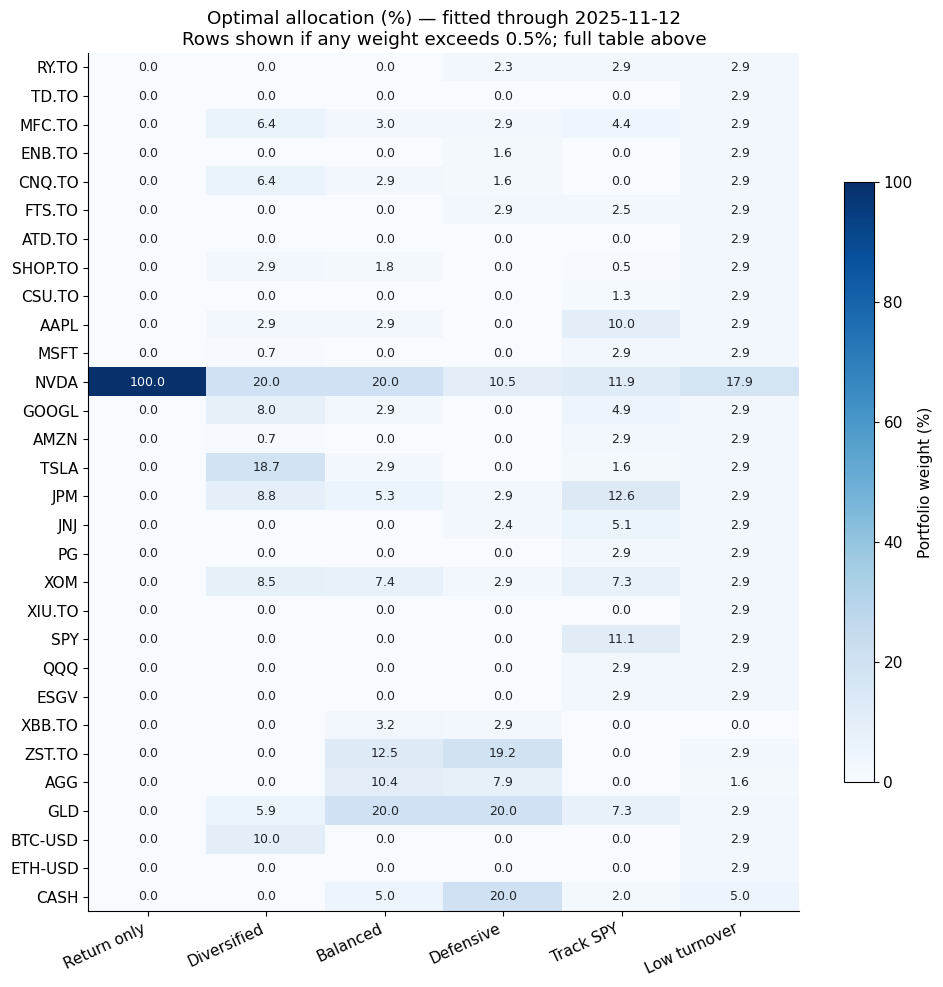

In [10]:
fig, ax = plt.subplots(figsize=(10,10))
shown = ws.loc[ws.max(axis=1) > .005] * 100
im = ax.imshow(shown, aspect='auto', cmap='Blues', vmin=0, vmax=100)
ax.set_xticks(range(len(shown.columns)), shown.columns, rotation=25, ha='right')
ax.set_yticks(range(len(shown)), shown.index)
for i in range(len(shown)):
    for j in range(len(shown.columns)):
        value = shown.iloc[i,j]
        ax.text(j,i,f'{value:.1f}',ha='center',va='center',fontsize=9,
                color='white' if value>55 else '#20242b')
ax.set_title(f'Optimal allocation (%) — fitted through {fit_end.date()}\nRows shown if any weight exceeds 0.5%; full table above')
fig.colorbar(im, ax=ax, label='Portfolio weight (%)', shrink=.7)
fig.tight_layout()
fig.savefig(OUT/'weights.png',dpi=150,bbox_inches='tight')
plt.show()

### Compare expected reward and fitted risk
Expected return is monthly; trading cost is paid once. Risk metrics describe the fitted constant-weight portfolio, not the future buy-and-hold path. A constraint is “binding” when it is effectively at its limit.

In [11]:
comparison_rows = []
for name,s in solutions.items():
    w,cash = s['w'],s['cash']
    m = measures(w,cash)
    comparison_rows.append({'profile':name,
        'expected monthly %':100*(mu_month@w+rf_month*cash),
        'one-off cost %':100*KAPPA*m['turnover_max'],
        'net objective %':100*s['objective'], 'vol annual %':100*m['vol_max'],
        'CVaR95 session %':100*m['cvar_max'], 'beta':m['beta_max'],
        'TE annual %':100*m['te_max'], 'stress loss %':100*m['stress_max'],
        'asset HHI':m['hhi_max'], 'HHI incl cash':m['hhi_max']+cash**2,
        'asset effective N':w.sum()**2/m['hhi_max'] if m['hhi_max']>1e-12 else np.nan,
        'gross turnover %':100*m['turnover_max']})
comparison = pd.DataFrame(comparison_rows).set_index('profile')
comparison.to_csv(OUT/'portfolio_comparison.csv')
display(comparison[['expected monthly %','one-off cost %','net objective %','vol annual %','CVaR95 session %','beta']].round(3))
display(comparison[['TE annual %','stress loss %','asset HHI','HHI incl cash','asset effective N','gross turnover %']].round(3))
exposures = pd.DataFrame({name:{**{key:float(mask@s['w']) for key,mask in masks.items()},
                                'cash':s['cash']} for name,s in solutions.items()}).T
display((100*exposures).round(2).rename_axis('Exposures (%; columns overlap)'))
exposures.to_csv(OUT/'portfolio_exposures.csv')

,expected monthly %,one-off cost %,net objective %,vol annual %,CVaR95 session %,beta
profile,,,,,,
Return only,3.360,0.184,3.176,53.255,7.058,2.151
Diversified,2.083,0.123,1.959,25.656,3.573,1.230
Balanced,1.742,0.112,1.630,15.000,2.089,0.727
Defensive,1.279,0.102,1.177,7.380,1.000,0.324
Track SPY,1.727,0.089,1.638,17.225,2.488,0.961
Low turnover,1.720,0.025,1.695,18.129,2.563,0.937


,TE annual %,stress loss %,asset HHI,HHI incl cash,asset effective N,gross turnover %
profile,,,,,,
Return only,43.163,30.000,1.000,1.000,1.000,184.194
Diversified,15.098,30.428,0.120,0.120,8.333,123.318
Balanced,9.564,15.000,0.120,0.122,7.521,111.719
Defensive,12.587,9.500,0.100,0.140,6.400,101.992
Track SPY,5.000,26.840,0.076,0.077,12.592,89.178
Low turnover,8.435,27.806,0.054,0.057,16.643,25.000


,equity,bond,crypto,gold,usd,canada,direct_tech,etf,cash
Exposures (%; columns overlap),,,,,,,,,
Return only,100.00,0.00,0.00,0.00,100.00,0.00,100.00,0.00,0.0
Diversified,84.08,0.00,10.00,5.92,84.28,15.72,26.50,5.95,0.0
Balanced,49.00,26.00,0.00,20.00,71.71,23.29,24.68,46.00,5.0
Defensive,30.00,30.00,0.00,20.00,46.57,33.43,10.51,50.00,20.0
Track SPY,90.69,0.00,0.00,7.31,86.43,11.57,26.61,24.27,2.0
Low turnover,81.77,4.52,5.81,2.90,63.06,31.94,29.52,19.03,5.0


### Sensitivity: change only the volatility cap
Keep the diversified limits, 5% minimum cash and 20% minimum bonds fixed. Increasing the volatility cap expands the feasible set, so the optimal objective should not decrease. This isolates one constraint's effect; it does not choose a cap using holdout performance.

,vol cap %,status,achieved vol %,net monthly objective %,cash %
0,6.0,optimal,6.000,1.208,5.0
1,8.0,optimal,8.000,1.384,5.0
2,10.0,optimal,10.000,1.509,5.0
3,12.0,optimal,12.000,1.611,5.0
4,15.0,optimal,15.000,1.701,5.0
5,20.0,optimal,20.000,1.721,5.0
6,25.0,optimal,23.602,1.731,5.0
7,30.0,optimal,23.602,1.731,5.0


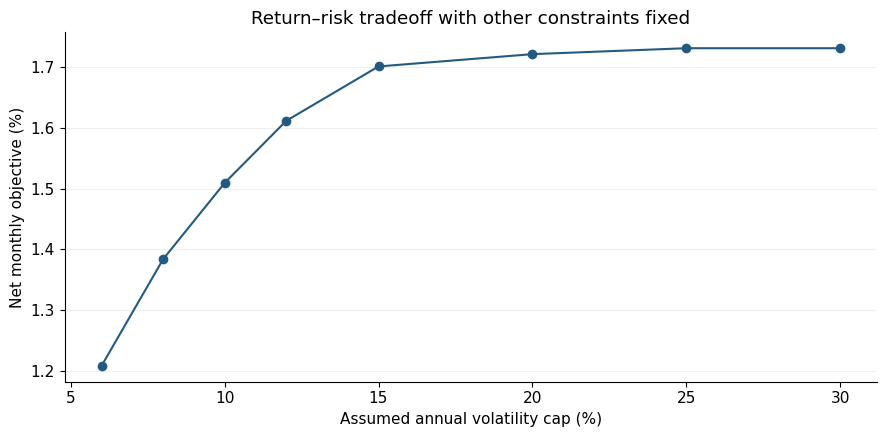

In [12]:
sensitivity_rows=[]
sensitivity_weights={}
for cap in [.06,.08,.10,.12,.15,.20,.25,.30]:
    limits=dict(base,cash_min=.05,bond_min=.20,vol_max=cap)
    s=solve_portfolio(limits)
    if s['status'] != 'optimal':
        sensitivity_rows.append({'vol cap %':cap*100,'status':s['status']})
        continue
    assert measures(s['w'],s['cash'])['vol_max'] <= cap+TOL
    sensitivity_rows.append({'vol cap %':cap*100,'status':s['status'],
        'achieved vol %':100*measures(s['w'],s['cash'])['vol_max'],
        'net monthly objective %':100*s['objective'],'cash %':100*s['cash']})
    sensitivity_weights[f'{cap:.0%} cap']=np.r_[s['w'],s['cash']]
sensitivity=pd.DataFrame(sensitivity_rows)
assert (sensitivity['net monthly objective %'].dropna().diff().dropna() >= -1e-5).all()
display(sensitivity.round(3))
sensitivity.to_csv(OUT/'volatility_sensitivity.csv',index=False)
pd.DataFrame(sensitivity_weights,index=tickers+['CASH']).to_csv(OUT/'sensitivity_weights.csv')
fig,ax=plt.subplots(figsize=(9,4.5))
ax.plot(sensitivity['vol cap %'],sensitivity['net monthly objective %'],'o-',color='#245a81')
ax.set(xlabel='Assumed annual volatility cap (%)',ylabel='Net monthly objective (%)',
       title='Return–risk tradeoff with other constraints fixed')
ax.grid(axis='y',alpha=.2)
fig.tight_layout();fig.savefig(OUT/'sensitivity.png',dpi=150);plt.show()

## 5. Holdout: what happened after choosing the weights?
Freeze the fitted allocations, charge the initial estimated cost by scaling starting wealth, then **buy and hold** through the final year. Dividends are embedded in adjusted returns; cash follows the lagged overnight-rate proxy. No later trading, costs or optimization occur. Weights drift, so initial constraints need not remain satisfied.

SPY in CAD is a gross benchmark with no entry cost; equal-weight + 10% cash matches the assumed existing holdings and has no initial turnover. This is a retrospective demonstration, not a point-in-time investment backtest: the universe was selected in 2026 and adjusted prices are the supplied revised snapshot.

In [13]:
asset_growth=(1+test).cumprod()
cash_growth=(1+cash_returns.loc[test.index]).cumprod()
paths={}
for name,s in solutions.items():
    cost=KAPPA*np.abs(s['w']-previous_w).sum()
    paths[name]=(asset_growth@s['w']+cash_growth*s['cash'])*(1-cost)
paths['SPY (gross)']=asset_growth['SPY']
paths['Existing holdings']=asset_growth@previous_w+cash_growth*.10
wealth=pd.DataFrame(paths)
wealth=pd.concat([pd.DataFrame(1.0,index=[fit_end],columns=wealth.columns),wealth])
realized=wealth.pct_change().iloc[1:]
years=(wealth.index[-1]-fit_end).days/365.25
hold_ann=len(realized)/years
hold_rf=cash_returns.loc[realized.index].to_numpy()
hold_bench=test.SPY.to_numpy()
rows=[]
for name in wealth:
    r=realized[name].to_numpy()
    vol=r.std(ddof=1)*np.sqrt(hold_ann)
    dd=np.sqrt(np.mean(np.minimum(r,0)**2)*hold_ann)
    cagr=wealth[name].iloc[-1]**(1/years)-1
    mdd=(wealth[name]/wealth[name].cummax()-1).min()
    active=r-hold_bench
    te=active.std(ddof=1)*np.sqrt(hold_ann)
    b=np.cov(r,hold_bench,ddof=1)[0,1]/np.var(hold_bench,ddof=1)
    excess=(r-hold_rf).mean()*hold_ann
    rows.append({'portfolio':name,'total return %':100*(wealth[name].iloc[-1]-1),
       'CAGR %':100*cagr,'vol annual %':100*vol,'max drawdown %':100*mdd,
       'CVaR95 session %':100*cvar_loss(r),'Sharpe':excess/vol if vol>1e-10 else np.nan,
       'Sortino (target 0)':r.mean()*hold_ann/dd if dd>1e-10 else np.nan,
       'alpha annual %':100*((r-hold_rf).mean()-b*(hold_bench-hold_rf).mean())*hold_ann,
       'information ratio':active.mean()*hold_ann/te if te>1e-10 else np.nan,
       'Calmar':cagr/abs(mdd) if abs(mdd)>1e-10 else np.nan,
       'Treynor':excess/b if b>1e-6 else np.nan})
holdout=pd.DataFrame(rows).set_index('portfolio')
holdout.to_csv(OUT/'holdout_metrics.csv')
wealth.to_csv(OUT/'holdout_wealth.csv')
display(holdout[['total return %','CAGR %','vol annual %','max drawdown %','CVaR95 session %','Sharpe']].round(3))
display(holdout[['Sortino (target 0)','alpha annual %','information ratio','Calmar','Treynor']].round(3))

,total return %,CAGR %,vol annual %,max drawdown %,CVaR95 session %,Sharpe
portfolio,,,,,,
Return only,-12.668,-12.676,38.478,-30.430,5.200,-0.218
Diversified,5.972,5.976,16.221,-10.350,2.491,0.301
Balanced,4.535,4.539,11.816,-7.568,1.795,0.245
Defensive,4.861,4.865,7.932,-4.500,1.215,0.357
Track SPY,15.758,15.769,11.496,-5.782,1.664,1.137
Low turnover,9.750,9.757,11.287,-5.807,1.712,0.683
SPY (gross),13.985,13.995,14.120,-8.536,1.973,0.840
Existing holdings,12.635,12.644,7.990,-4.142,1.224,1.251


,Sortino (target 0),alpha annual %,information ratio,Calmar,Treynor
portfolio,,,,,
Return only,-0.225,-28.348,-0.638,-0.417,-0.050
Diversified,0.603,-5.775,-0.684,0.577,0.054
Balanced,0.604,-3.960,-0.861,0.600,0.050
Defensive,0.882,-0.888,-0.771,1.081,0.090
Track SPY,1.931,4.438,0.188,2.727,0.180
Low turnover,1.235,-0.373,-0.560,1.680,0.113
SPY (gross),1.457,0.000,NaN,1.640,0.119
Existing holdings,2.187,4.581,-0.207,3.053,0.219


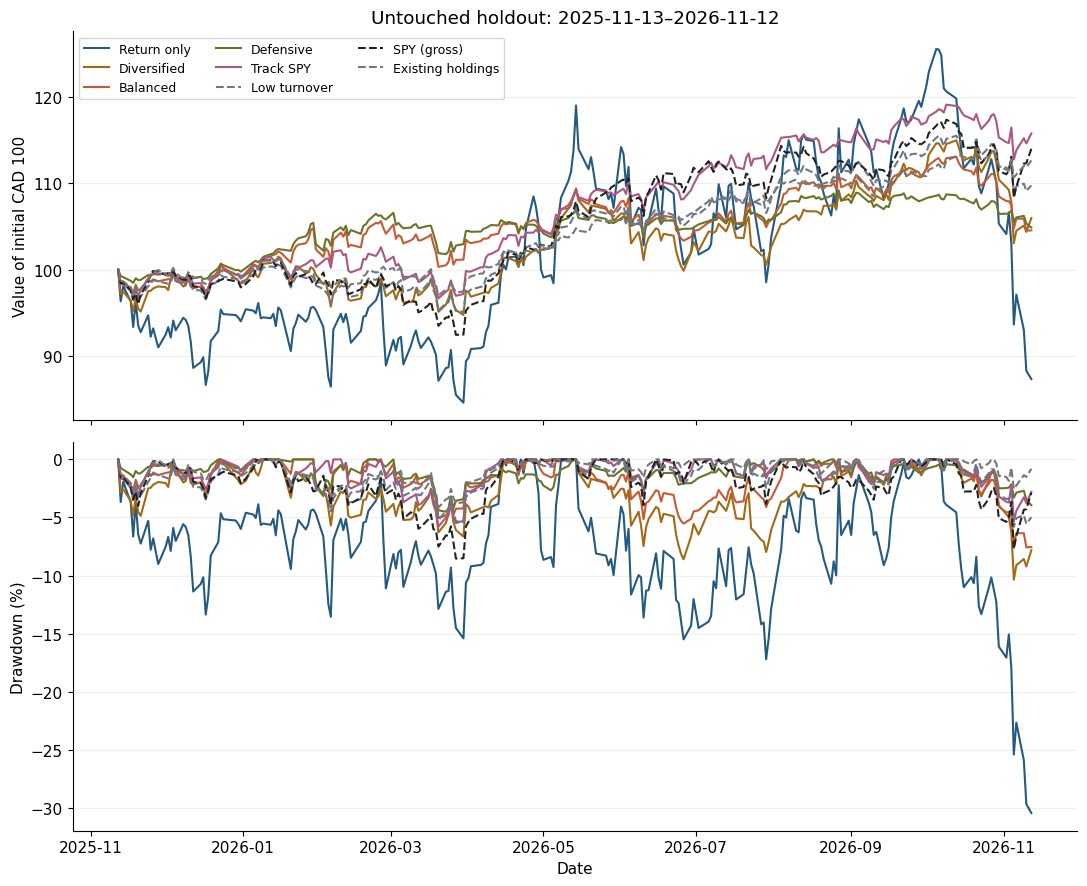

In [14]:
colors={'Return only':'#245a81','Diversified':'#a46913','Balanced':'#c65a31',
        'Defensive':'#6a7429','Track SPY':'#ac5682','Low turnover':'#697889',
        'SPY (gross)':'#222222','Existing holdings':'#777777'}
fig,axes=plt.subplots(2,1,figsize=(11,9),sharex=True)
for name in wealth:
    style='--' if name in ['SPY (gross)','Existing holdings','Low turnover'] else '-'
    axes[0].plot(wealth.index,wealth[name]*100,color=colors[name],ls=style,label=name)
    axes[1].plot(wealth.index,100*(wealth[name]/wealth[name].cummax()-1),color=colors[name],ls=style)
axes[0].set(title=f'Untouched holdout: {test.index[0].date()}–{test.index[-1].date()}',ylabel='Value of initial CAD 100')
axes[0].legend(ncol=3,fontsize=9,loc='upper left')
axes[1].set(ylabel='Drawdown (%)',xlabel='Date')
for ax in axes: ax.grid(axis='y',alpha=.2)
fig.tight_layout();fig.savefig(OUT/'holdout.png',dpi=150,bbox_inches='tight');plt.show()

## 6. Takeaways and changes to try
The following summary is generated from the computed results. Forecast return and realized return are different quantities; the holdout does not retroactively change the selected weights.

In [15]:
winner=comparison['net objective %'].idxmax()
realized_winner=holdout.loc[list(profiles),'total return %'].idxmax()
lines=[f"**Highest fitted objective:** {winner}, {comparison.loc[winner,'net objective %']:.2f}% net for one month.",
       f"**Highest holdout return among the six demos:** {realized_winner}, {holdout.loc[realized_winner,'total return %']:.2f}% over the holdout; this was not the optimization target."]
for name in ['Balanced','Defensive','Low turnover']:
    top=ws[name].sort_values(ascending=False).head(4)
    description=', '.join(f'{ticker} {weight:.1%}' for ticker,weight in top.items())
    lines.append(f"**{name}:** {description}. Fitted annual volatility {comparison.loc[name,'vol annual %']:.1f}%; holdout return {holdout.loc[name,'total return %']:.1f}%.")
display(Markdown('\n\n'.join(lines)))

**Highest fitted objective:** Return only, 3.18% net for one month.

**Highest holdout return among the six demos:** Track SPY, 15.76% over the holdout; this was not the optimization target.

**Balanced:** NVDA 20.0%, GLD 20.0%, ZST.TO 12.5%, AGG 10.4%. Fitted annual volatility 15.0%; holdout return 4.5%.

**Defensive:** CASH 20.0%, GLD 20.0%, ZST.TO 19.2%, NVDA 10.5%. Fitted annual volatility 7.4%; holdout return 4.9%.

**Low turnover:** NVDA 17.9%, CASH 5.0%, BTC-USD 2.9%, TSLA 2.9%. Fitted annual volatility 18.1%; holdout return 9.7%.

### Limits and next experiments
- Estimated means are noisy; concentration can reflect a few historical winners. Change `SHRINK` (e.g. 0, 0.5, 1), the training window, costs or profiles, then rerun. Caps are illustrative policy choices, not suitability recommendations.
- The risk limits describe the fitted sample; they do not guarantee future volatility, loss limits or cash yields. A stress result covers only the specified joint shock. No uncertainty interval is estimated.
- Common-calendar aggregation and lagged crypto prices affect covariance and tail losses. Prices and FX are not synchronized trade quotes. No spreads, taxes, market impact, liquidity limits or ETF look-through are modeled.
- The 2026-selected universe and revised price history retain survivorship and snapshot bias. The holdout separates return fitting from evaluation but does not remove those biases. Monthly CPI/unemployment data are not used, avoiding reference-date/release-date leakage.
- To add listing exposure assumptions, use `usd_max`, `canada_min` or `gold_min` in a profile. Verify ETF holdings externally before adding true sector or ESG restrictions.

**Outputs:** `portfolio_weights.csv` contains the requested `ws`; `constraint_audit.csv` lists every active limit, actual value and slack. Indicator, comparison, sensitivity and holdout CSVs provide the supporting calculations. All are generated from the local snapshot identified in `input_manifest.csv`.

**Validation:** All code cells executed top to bottom. All six solver results passed budget, feasibility and independent metric checks; the deliberately conflicting profile was rejected. All three saved figures were visually inspected. A full notebook/HTML browser preview was unavailable in this session; open `demo.ipynb` in VS Code and select the project Python kernel to inspect or rerun it.